# Aprendizaje no supervisado

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN, KMeans
import pandas as pd
from matplotlib.ticker import PercentFormatter

In [ ]:
Funciones a utilizar

In [2]:
# Radio medio aproximado de la Tierra en kilómetros.
radio_tierra_km = 6371.0088

# Función para implementar DBSCAN geográfico

def dbscan_geo(coordenadas_radianes, eps_km, min_samples=5):
    """
    Aplica DBSCAN utilizando distancia haversine.

    Parámetros
    ----------
    coordenadas_radianes:
        Matriz de coordenadas [latitud, longitud] en radianes.

    eps_km:
        Radio máximo de vecindad expresado en kilómetros.

    min_samples:
        Número mínimo de observaciones en una vecindad
        para identificar un punto central.

    Retorna
    -------
    etiquetas:
        Cluster asignado a cada observación.

        0, 1, 2, ... : identificadores de clusters.
        -1           : observaciones clasificadas como ruido.
    """

    # Convertimos la distancia de kilómetros a radianes.
    # Ejemplo: 1 km / 6371.0088 km ≈ 0.000157 radianes.

    eps_rad = eps_km / radio_tierra_km

    modelo = DBSCAN(
        eps=eps_rad,
        min_samples=min_samples,
        metric="haversine",
        algorithm="ball_tree"
    )

    # fit_predict ajusta DBSCAN y devuelve directamente
    # el cluster asignado a cada observación.
    etiquetas = modelo.fit_predict(coordenadas_radianes)

    return etiquetas

# 1. Datos

Importamos la base de datos

In [18]:
url = "https://raw.githubusercontent.com/ElenaVillano/databases/refs/heads/main/db_falsas_alarmas.csv"
df = pd.read_csv(url)
df.head(1)

,folio,fecha_hora_creacion,fecha_hora_cierre,tipo_incidente_c4,incidente_c4,alcaldia_inicio,codigo_cierre,clas_con_f_alarma,tipo_entrada,alcaldia_cierre,alcaldia_catalogo,colonia_catalogo,longitud,latitud
0,C5/20220923/04016,2022-09-23 18:38:34,2022-09-23 22:22:27,Accidente,Choque sin lesionados,VENUSTIANO CARRANZA,A,EMERGENCIA,LLAMADA DEL 911,VENUSTIANO CARRANZA,Venustiano Carranza,20 De Noviembre,-99.108352,19.44392


Quitamos algunos puntos fuera del polígono de la CDMX

In [19]:
df['cordenada_fuera_cdmx'] = ~(df['latitud'].between(19.0482, 19.5928) &df['longitud'].between(-99.3649, -98.9403))
df = df[df['cordenada_fuera_cdmx']==False]

In [20]:
df.columns

Index(['folio', 'fecha_hora_creacion', 'fecha_hora_cierre',
       'tipo_incidente_c4', 'incidente_c4', 'alcaldia_inicio', 'codigo_cierre',
       'clas_con_f_alarma', 'tipo_entrada', 'alcaldia_cierre',
       'alcaldia_catalogo', 'colonia_catalogo', 'longitud', 'latitud',
       'cordenada_fuera_cdmx'],
      dtype='str')

In [21]:
# Ver el tipo de valor
df[['longitud', 'latitud']].dtypes

longitud    float64
latitud     float64
dtype: object

In [22]:
# Ver los datos 
df[['longitud', 'latitud']].head(1)

,longitud,latitud
0,-99.108352,19.44392


Ver los valores faltantes

In [23]:
#No hay valores faltantes

df[['latitud', 'longitud']].isna().sum()

latitud     0
longitud    0
dtype: int64

Tomamos una muestra 

El conjunto de información es muy grande y el algoritmo puede tardar en correr mucho o no encontrar las agrupaciones correctas

In [24]:
df_muestra = df.sample(
    frac=0.05,
    random_state=96
).copy()

print(df_muestra.shape)

(6213, 15)


In [25]:
## Seleciconamos solamente las columnas de longitud y latitud
coordenadas = df_muestra[['longitud','latitud']] 

# 2. DBSCAN

In [26]:
coordenadas_rad = np.radians(coordenadas)
# Radio medio aproximado de la Tierra en kilómetros.
radio_tierra_km = 6371.0088

# Función para implementar DBSCAN geográfico

def dbscan_geo(coordenadas_radianes, eps_km, min_samples=5):
    """
    Aplica DBSCAN utilizando distancia haversine.

    Parámetros
    ----------
    coordenadas_radianes:
        Matriz de coordenadas [latitud, longitud] en radianes.

    eps_km:
        Radio máximo de vecindad expresado en kilómetros.

    min_samples:
        Número mínimo de observaciones en una vecindad
        para identificar un punto central.

    Retorna
    -------
    etiquetas:
        Cluster asignado a cada observación.

        0, 1, 2, ... : identificadores de clusters.
        -1           : observaciones clasificadas como ruido.
    """

    # Convertimos la distancia de kilómetros a radianes.
    # Ejemplo: 1 km / 6371.0088 km ≈ 0.000157 radianes.

    eps_rad = eps_km / radio_tierra_km

    modelo = DBSCAN(
        eps=eps_rad,
        min_samples=min_samples,
        metric="haversine",
        algorithm="ball_tree"
    )

    # fit_predict ajusta DBSCAN y devuelve directamente
    # el cluster asignado a cada observación.
    etiquetas = modelo.fit_predict(coordenadas_radianes)

    return etiquetas

Implementación sencilla de DBSCAN, con la función de clase 

In [27]:
df_geo = df_muestra.reset_index(drop=True).copy()

coordenadas = df_geo[['latitud', 'longitud']].to_numpy()
coordenadas_rad = np.radians(coordenadas)
prueba  =dbscan_geo(coordenadas_rad, 3, min_samples=2)
grupos = len(set(prueba) - {-1})
ruido = np.mean(prueba == -1)

print(grupos)

1


# 3. Parámetros

In [15]:
combinaciones = [
    {'eps_km': 0.5, 'min_samples': 5},
    {'eps_km': 1.0, 'min_samples': 10},
    {'eps_km': 1.5, 'min_samples': 15},
    {'eps_km': 2.0, 'min_samples': 20}
]

etiquetas_por_modelo = {}
resultados_dbscan = []

for c in combinaciones:
    eps_km = c['eps_km']
    min_samples = c['min_samples']

    nombre = f"eps={eps_km} km, min_samples={min_samples}"

    etiquetas = dbscan_geo(
        coordenadas_rad,
        eps_km=eps_km,
        min_samples=min_samples
    )

    etiquetas_por_modelo[nombre] = etiquetas

    clusters = [
        etiqueta for etiqueta in np.unique(etiquetas)
        if etiqueta != -1
    ]

    tamanos_clusters = [
        int((etiquetas == cluster).sum())
        for cluster in clusters
    ]

    mascara_ruido = etiquetas == -1

    resultados_dbscan.append({
        'eps_km': eps_km,
        'min_samples': min_samples,
        'numero_clusters': len(clusters),
        'tamaño_min_cluster': (
            min(tamanos_clusters) if tamanos_clusters else np.nan
        ),
        'tamaño_max_cluster': (
            max(tamanos_clusters) if tamanos_clusters else np.nan
        ),
        'tamaño_promedio_cluster': (
            np.mean(tamanos_clusters) if tamanos_clusters else np.nan
        ),
        'observaciones_ruido': int(mascara_ruido.sum()),
        'proporcion_ruido': mascara_ruido.mean()
    })

df_resultados_dbscan = pd.DataFrame(resultados_dbscan)

display(
    df_resultados_dbscan.style.format({
        'tamaño_promedio_cluster': '{:.1f}',
        'proporcion_ruido': '{:.1%}'
    })
)

,eps_km,min_samples,numero_clusters,tamaño_min_cluster,tamaño_max_cluster,tamaño_promedio_cluster,observaciones_ruido,proporcion_ruido
0,0.500000,5,61,4,4737,93.9,487,7.8%
1,1.000000,10,7,10,5929,863.0,172,2.8%
2,1.500000,15,5,12,6064,1225.2,87,1.4%
3,2.000000,20,3,16,6094,2042.3,86,1.4%


Los resultados muestran que en cualquiera de las configuraciones un solo clúster concentra la mayor cantidad de información. Por ejemplo, en el primero son 61 clústeres, pero de todos modos el primero tiene la mayor parte, incluso aunque te sobren otros 60

Por ejemplo, en la primera configuración hay 61 clústeres. El más grande reúne 4,737 de los 5,726 reportes asignados a algún clúster, es decir, alrededor de 82.7%. Los otros 60 reúnen en conjunto los 989 reportes restantes. En las otras configuraciones, el clúster más grande concentra entre 98% y 99% de los reportes asignados.

Esto es más fácil de ver en los mapas, ya que la mayor zona o la mayor área es de color azul y los otros glóster están indicados en otros colores.


# 4. Interpretación

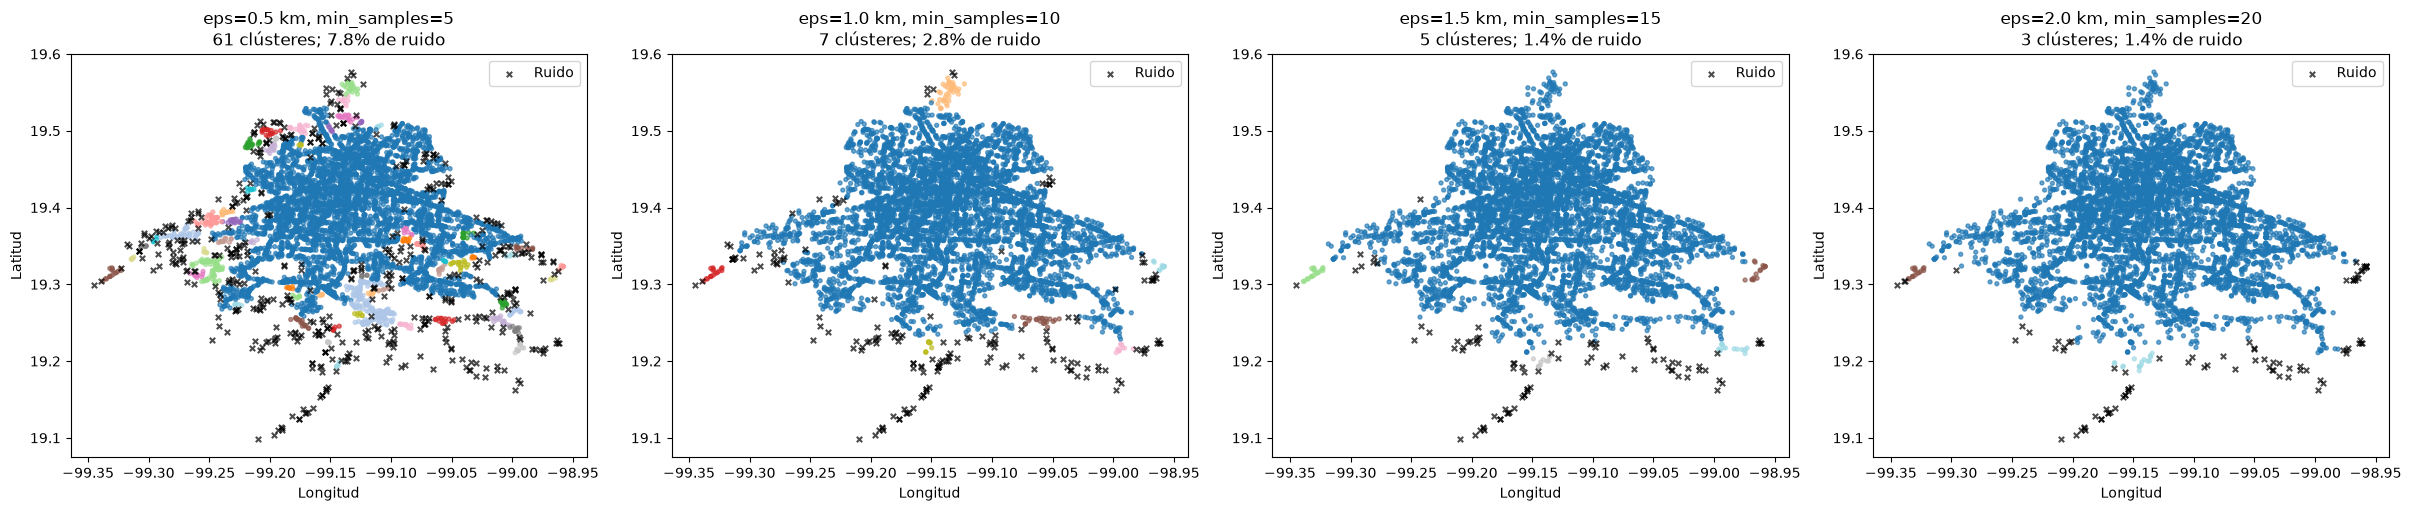

In [16]:
# df_geo debe conservar el mismo orden usado para crear coordenadas
df_geo = df.reset_index(drop=True).copy()

fig, axes = plt.subplots(
    1,
    len(etiquetas_por_modelo),
    figsize=(6 * len(etiquetas_por_modelo), 5),
    constrained_layout=True
)

axes = np.atleast_1d(axes)

for ax, (nombre_modelo, etiquetas) in zip(
    axes,
    etiquetas_por_modelo.items()
):
    mascara_ruido = etiquetas == -1
    numero_clusters = len(set(etiquetas) - {-1})
    proporcion_ruido = mascara_ruido.mean()

    ax.scatter(
        coordenadas[~mascara_ruido, 1],
        coordenadas[~mascara_ruido, 0],
        c=etiquetas[~mascara_ruido],
        cmap="tab20",
        s=8,
        alpha=0.65
    )

    ax.scatter(
        coordenadas[mascara_ruido, 1],
        coordenadas[mascara_ruido, 0],
        color="black",
        marker="x",
        s=15,
        alpha=0.7,
        label="Ruido"
    )

    ax.set_title(
        f"{nombre_modelo}\n"
        f"{numero_clusters} clústeres; {proporcion_ruido:.1%} de ruido"
    )
    ax.set_xlabel("Longitud")
    ax.set_ylabel("Latitud")
    ax.legend()

plt.show()

In [17]:
df_muestra['clas_con_f_alarma'].unique()

<StringArray>
['URGENCIAS MEDICAS', 'EMERGENCIA', 'DELITO', 'FALSA ALARMA']
Length: 4, dtype: str